In [1]:
import os
import glob
import zipfile
import sqlite3
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Upload and load the dataset

In [2]:
# If you are using Google Colab, this opens a file picker.
# Upload either AB_NYC_2019.csv.zip or AB_NYC_2019.csv.
from google.colab import files

uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))

Saving AB_NYC_2019.csv.zip to AB_NYC_2019.csv.zip
Uploaded files: ['AB_NYC_2019.csv.zip']


In [3]:
# Find the uploaded CSV or ZIP file.
data_dir = "/content"
zip_files = glob.glob(os.path.join(data_dir, "*.zip"))
csv_files = glob.glob(os.path.join(data_dir, "*.csv"))

if zip_files:
    extract_dir = "/content/airbnb_data"
    os.makedirs(extract_dir, exist_ok=True)
    with zipfile.ZipFile(zip_files[0], "r") as zf:
        zf.extractall(extract_dir)
    csv_files = glob.glob(os.path.join(extract_dir, "**", "*.csv"), recursive=True)

if not csv_files:
    raise FileNotFoundError("No CSV found. Upload AB_NYC_2019.csv.zip or AB_NYC_2019.csv.")

# Prefer the NYC 2019 file if multiple CSV files exist.
csv_path = next((p for p in csv_files if "nyc" in os.path.basename(p).lower() or "2019" in os.path.basename(p).lower()), csv_files[0])
df_raw = pd.read_csv(csv_path)

print("Loaded file:", csv_path)
print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
display(df_raw.head())

Loaded file: /content/airbnb_data/AB_NYC_2019.csv
Rows: 48,895 | Columns: 16


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.65,-73.97,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75,-73.98,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.81,-73.94,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.69,-73.96,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.80,-73.94,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


## 3. Understand the data

In [4]:
print("Shape:", df_raw.shape)
print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types and non-null counts:")
df_raw.info()

print("\nDescriptive statistics:")
display(df_raw.describe(include="all").T)

Shape: (48895, 16)

Column names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude      

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,"48,895.00",NaN,NaN,NaN,"19,017,143.24","10,983,108.39","2,539.00","9,471,945.00","19,677,284.00","29,152,178.50","36,487,245.00"
name,48879,47905,Hillside Hotel,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
host_id,"48,895.00",NaN,NaN,NaN,"67,620,010.65","78,610,967.03","2,438.00","7,822,033.00","30,793,816.00","107,434,423.00","274,321,313.00"
host_name,48874,11452,Michael,417,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neighbourhood_group,48895,5,Manhattan,21661,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neighbourhood,48895,221,Williamsburg,3920,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,"48,895.00",NaN,NaN,NaN,40.73,0.05,40.50,40.69,40.72,40.76,40.91
longitude,"48,895.00",NaN,NaN,NaN,-73.95,0.05,-74.24,-73.98,-73.96,-73.94,-73.71
room_type,48895,3,Entire home/apt,25409,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,"48,895.00",NaN,NaN,NaN,152.72,240.15,0.00,69.00,106.00,175.00,"10,000.00"


In [5]:
# Data dictionary for the main fields in this dataset
data_dictionary = pd.DataFrame({
    "column": df_raw.columns,
    "meaning": [
        "Unique listing identifier",
        "Listing title",
        "Host identifier",
        "Host name",
        "Borough / neighbourhood group",
        "Specific neighbourhood",
        "Latitude",
        "Longitude",
        "Room/accommodation type",
        "Listed nightly price in USD",
        "Minimum nights required",
        "Total number of reviews",
        "Date of the most recent review",
        "Average reviews per month",
        "Number of listings managed by this host",
        "Days available during the year (0–365)"
    ]
})
display(data_dictionary)

,column,meaning
0,id,Unique listing identifier
1,name,Listing title
2,host_id,Host identifier
3,host_name,Host name
4,neighbourhood_group,Borough / neighbourhood group
5,neighbourhood,Specific neighbourhood
6,latitude,Latitude
7,longitude,Longitude
8,room_type,Room/accommodation type
9,price,Listed nightly price in USD


## 4. Data quality audit

In [6]:
quality_report = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(2),
    "dtype": df_raw.dtypes.astype(str),
    "unique_values": df_raw.nunique(dropna=True)
}).sort_values("missing_percent", ascending=False)

display(quality_report)
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Duplicate listing IDs:", df_raw["id"].duplicated().sum() if "id" in df_raw else "id column missing")

,missing_count,missing_percent,dtype,unique_values
last_review,10052,20.56,object,1764
reviews_per_month,10052,20.56,float64,937
host_name,21,0.04,object,11452
name,16,0.03,object,47905
neighbourhood_group,0,0.00,object,5
neighbourhood,0,0.00,object,221
id,0,0.00,int64,48895
host_id,0,0.00,int64,37457
longitude,0,0.00,float64,14718
latitude,0,0.00,float64,19048


Exact duplicate rows: 0
Duplicate listing IDs: 0


## 5. Clean the data

In [7]:
df = df_raw.copy()

# Standardize text fields without changing the meaning of the data.
for col in ["name", "host_name", "neighbourhood_group", "neighbourhood", "room_type"]:
    if col in df.columns:
        df[col] = df[col].astype("string").str.strip()

# Parse dates; invalid date strings become missing.
df["last_review"] = pd.to_datetime(df["last_review"], errors="coerce")

# Remove exact duplicate rows. Listing ID should be unique; keep the first record if repeated.
df = df.drop_duplicates()
if "id" in df.columns:
    df = df.drop_duplicates(subset="id", keep="first")

# Missing listing/host names are labelled for analysis instead of dropping rows.
for col in ["name", "host_name"]:
    df[col] = df[col].fillna("Unknown")

# Missing review count means no reviews recorded in this snapshot; keep the count as zero.
df["number_of_reviews"] = pd.to_numeric(df["number_of_reviews"], errors="coerce").fillna(0)
# For listings with no review history, reviews_per_month missing is set to 0 for analysis.
df["reviews_per_month"] = pd.to_numeric(df["reviews_per_month"], errors="coerce").fillna(0)

# Convert numeric fields to numeric dtype.
numeric_cols = [
    "latitude", "longitude", "price", "minimum_nights", "number_of_reviews",
    "reviews_per_month", "calculated_host_listings_count", "availability_365"
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove records with impossible / unusable key values.
before = len(df)
df = df.dropna(subset=["neighbourhood_group", "neighbourhood", "room_type", "price"])
df = df[df["price"] > 0]
df = df[df["minimum_nights"] > 0]
df["availability_365"] = df["availability_365"].clip(lower=0, upper=365)
df["number_of_reviews"] = df["number_of_reviews"].clip(lower=0)
df["reviews_per_month"] = df["reviews_per_month"].clip(lower=0)

print(f"Rows before key-value filtering: {before:,}")
print(f"Rows after cleaning: {len(df):,}")
print(f"Rows removed by key-value filters: {before-len(df):,}")
print("Remaining exact duplicates:", df.duplicated().sum())
display(df.head())

Rows before key-value filtering: 48,895
Rows after cleaning: 48,884
Rows removed by key-value filters: 11
Remaining exact duplicates: 0


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.65,-73.97,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75,-73.98,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.81,-73.94,Private room,150,3,0,NaT,0.00,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.69,-73.96,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.80,-73.94,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [8]:
# Final quality checks
cleaning_summary = pd.DataFrame({
    "metric": [
        "Rows in raw dataset",
        "Rows in cleaned dataset",
        "Columns",
        "Missing listing names",
        "Missing last_review dates",
        "Listings with zero reviews",
        "Listings with price <= 0"
    ],
    "value": [
        len(df_raw), len(df), df.shape[1],
        int((df["name"] == "Unknown").sum()),
        int(df["last_review"].isna().sum()),
        int((df["number_of_reviews"] == 0).sum()),
        int((df["price"] <= 0).sum())
    ]
})
display(cleaning_summary)

,metric,value
0,Rows in raw dataset,48895
1,Rows in cleaned dataset,48884
2,Columns,16
3,Missing listing names,16
4,Missing last_review dates,10051
5,Listings with zero reviews,10051
6,Listings with price <= 0,0


## 6. Create analysis fields
For price charts, the full valid data remains available in `df`. Since a small number of very expensive listings can compress charts, we create a separate `df_price_viz` that displays listings up to the 99th percentile. This is **only for visualization**, not deletion from the main dataset.

In [9]:
df["price_band"] = pd.cut(
    df["price"],
    bins=[0, 100, 200, 500, np.inf],
    labels=["Budget (<= $100)", "Mid-range ($101–200)", "Premium ($201–500)", "Luxury (> $500)"],
    include_lowest=True
)

price_99 = df["price"].quantile(0.99)
df_price_viz = df[df["price"] <= price_99].copy()

print(f"99th percentile of nightly price: ${price_99:,.2f}")
print(f"Listings included in price-focused charts: {len(df_price_viz):,} of {len(df):,}")

99th percentile of nightly price: $799.00
Listings included in price-focused charts: 48,410 of 48,884


## 7. Key performance indicators (KPIs)

In [10]:
kpis = pd.DataFrame({
    "Metric": [
        "Valid listings",
        "Unique hosts",
        "Neighbourhoods",
        "Boroughs / neighbourhood groups",
        "Median nightly price (USD)",
        "Average nightly price (USD)",
        "Median minimum nights",
        "Listings with at least one review"
    ],
    "Value": [
        f"{len(df):,}",
        f"{df['host_id'].nunique():,}",
        f"{df['neighbourhood'].nunique():,}",
        f"{df['neighbourhood_group'].nunique():,}",
        f"${df['price'].median():,.2f}",
        f"${df['price'].mean():,.2f}",
        f"{df['minimum_nights'].median():,.0f}",
        f"{(df['number_of_reviews'] > 0).sum():,}"
    ]
})
display(kpis)

,Metric,Value
0,Valid listings,"48,884"
1,Unique hosts,"37,455"
2,Neighbourhoods,221
3,Boroughs / neighbourhood groups,5
4,Median nightly price (USD),$106.00
5,Average nightly price (USD),$152.76
6,Median minimum nights,3
7,Listings with at least one review,"38,833"


## 8. Visual analysis

### 8.1 Listing count by borough

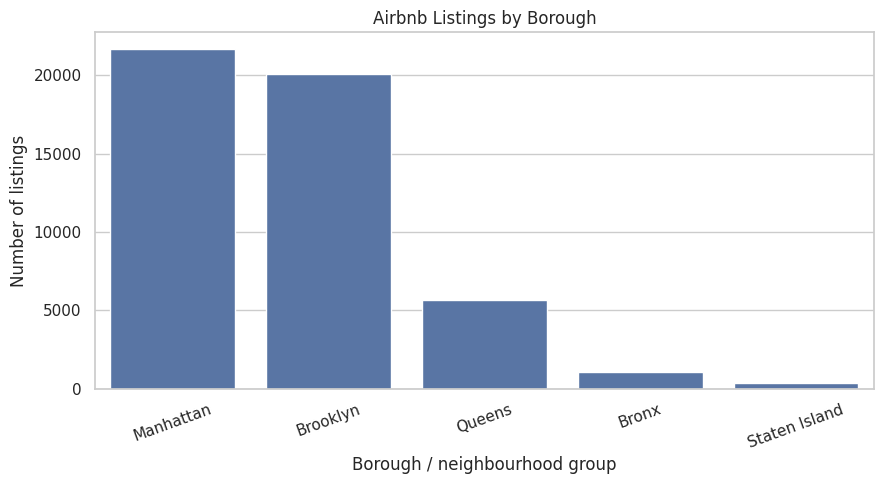

,listing_count
neighbourhood_group,
Manhattan,21660
Brooklyn,20095
Queens,5666
Bronx,1090
Staten Island,373


In [11]:
borough_counts = df["neighbourhood_group"].value_counts().sort_values(ascending=False)
plt.figure(figsize=(9, 5))
sns.barplot(x=borough_counts.index, y=borough_counts.values)
plt.title("Airbnb Listings by Borough")
plt.xlabel("Borough / neighbourhood group")
plt.ylabel("Number of listings")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
display(borough_counts.rename("listing_count").to_frame())

### 8.2 Room type distribution

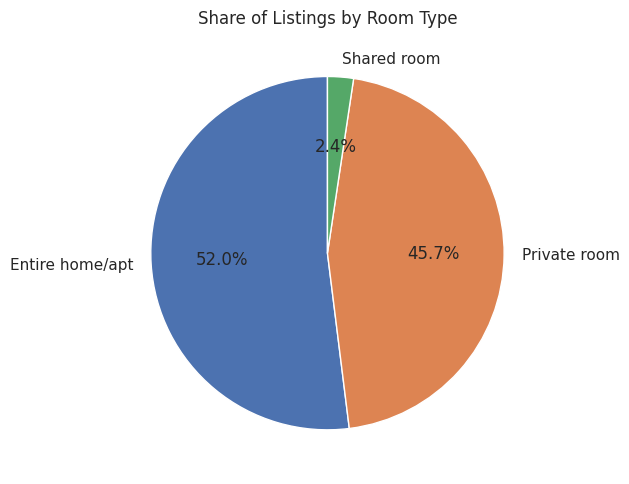

,listing_count
room_type,
Entire home/apt,25407
Private room,22319
Shared room,1158


In [12]:
room_counts = df["room_type"].value_counts()
plt.figure(figsize=(8, 5))
plt.pie(room_counts.values, labels=room_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Share of Listings by Room Type")
plt.tight_layout()
plt.show()
display(room_counts.rename("listing_count").to_frame())

### 8.3 Median price by borough and room type

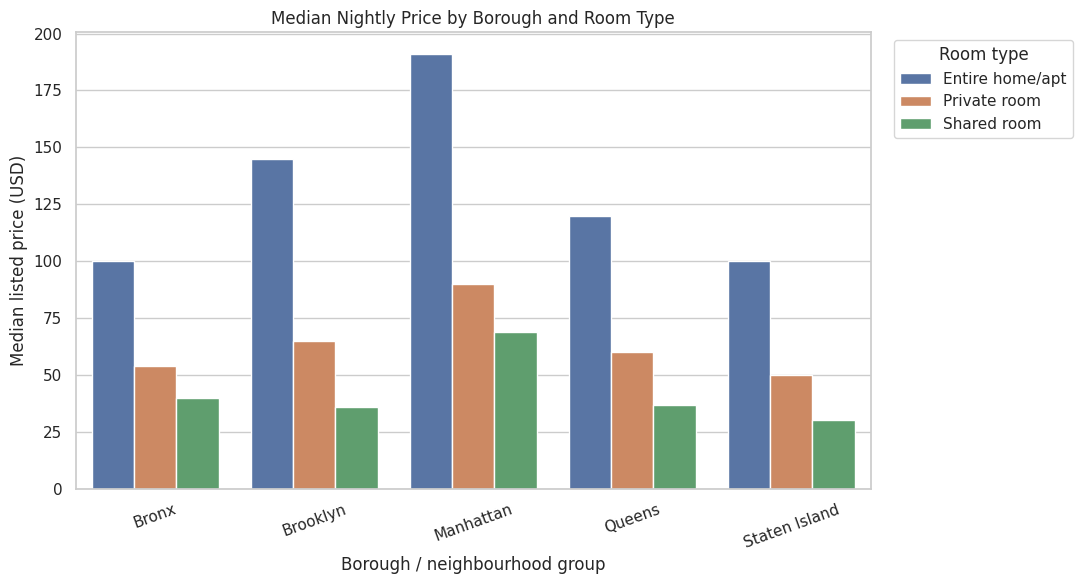

,neighbourhood_group,room_type,price
6,Manhattan,Entire home/apt,191.00
3,Brooklyn,Entire home/apt,145.00
9,Queens,Entire home/apt,120.00
12,Staten Island,Entire home/apt,100.00
0,Bronx,Entire home/apt,100.00
7,Manhattan,Private room,90.00
8,Manhattan,Shared room,69.00
4,Brooklyn,Private room,65.00
10,Queens,Private room,60.00
1,Bronx,Private room,54.00


In [13]:
price_by_borough_room = (
    df.groupby(["neighbourhood_group", "room_type"], observed=False)["price"]
      .median().reset_index()
)
plt.figure(figsize=(11, 6))
sns.barplot(data=price_by_borough_room, x="neighbourhood_group", y="price", hue="room_type")
plt.title("Median Nightly Price by Borough and Room Type")
plt.xlabel("Borough / neighbourhood group")
plt.ylabel("Median listed price (USD)")
plt.xticks(rotation=20)
plt.legend(title="Room type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
display(price_by_borough_room.sort_values("price", ascending=False))

### 8.4 Price distribution (up to 99th percentile for readability)

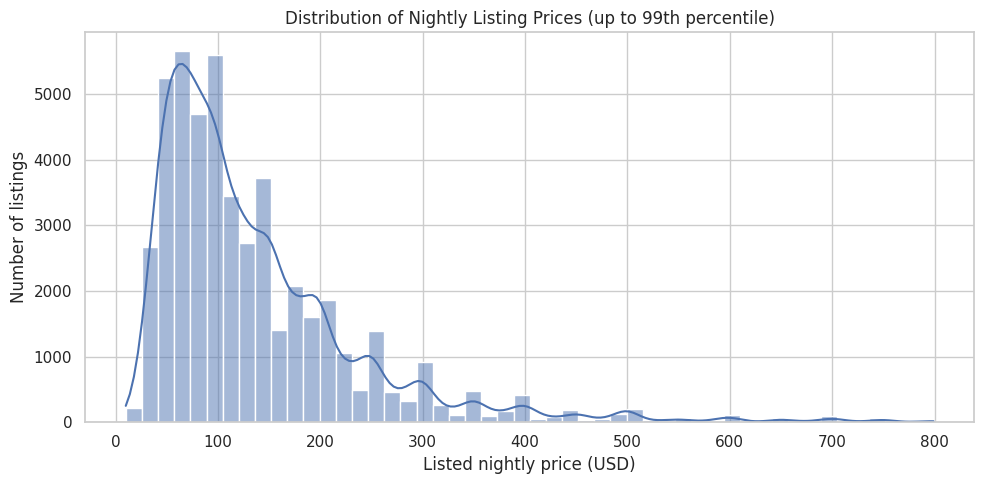

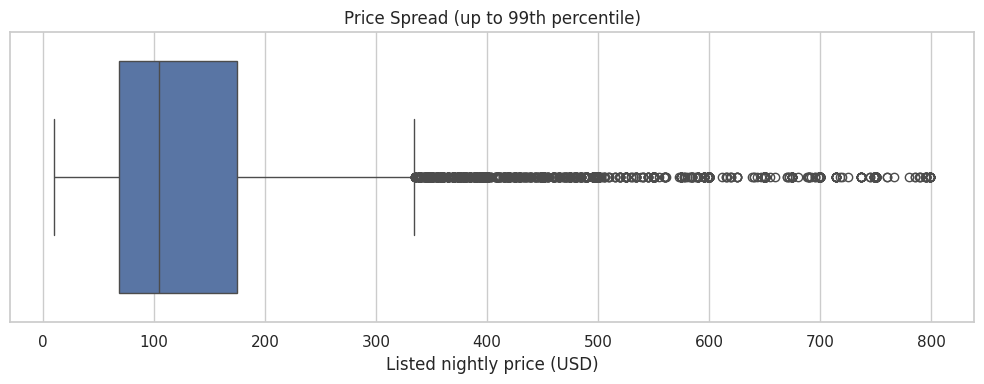

In [14]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df_price_viz, x="price", bins=50, kde=True)
plt.title("Distribution of Nightly Listing Prices (up to 99th percentile)")
plt.xlabel("Listed nightly price (USD)")
plt.ylabel("Number of listings")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
sns.boxplot(data=df_price_viz, x="price")
plt.title("Price Spread (up to 99th percentile)")
plt.xlabel("Listed nightly price (USD)")
plt.tight_layout()
plt.show()

### 8.5 Top 10 neighbourhoods by listing count

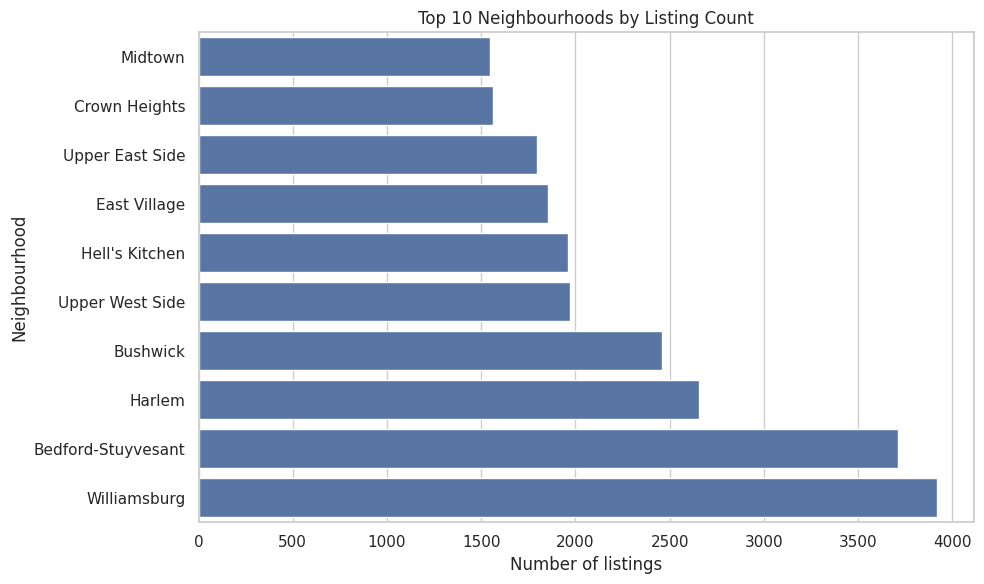

,listing_count
neighbourhood,
Williamsburg,3919
Bedford-Stuyvesant,3710
Harlem,2658
Bushwick,2462
Upper West Side,1971
Hell's Kitchen,1958
East Village,1853
Upper East Side,1798
Crown Heights,1564


In [15]:
top_neighbourhoods = df["neighbourhood"].value_counts().head(10).sort_values()
plt.figure(figsize=(10, 6))
sns.barplot(x=top_neighbourhoods.values, y=top_neighbourhoods.index)
plt.title("Top 10 Neighbourhoods by Listing Count")
plt.xlabel("Number of listings")
plt.ylabel("Neighbourhood")
plt.tight_layout()
plt.show()
display(top_neighbourhoods.sort_values(ascending=False).rename("listing_count").to_frame())

### 8.6 Price vs review count

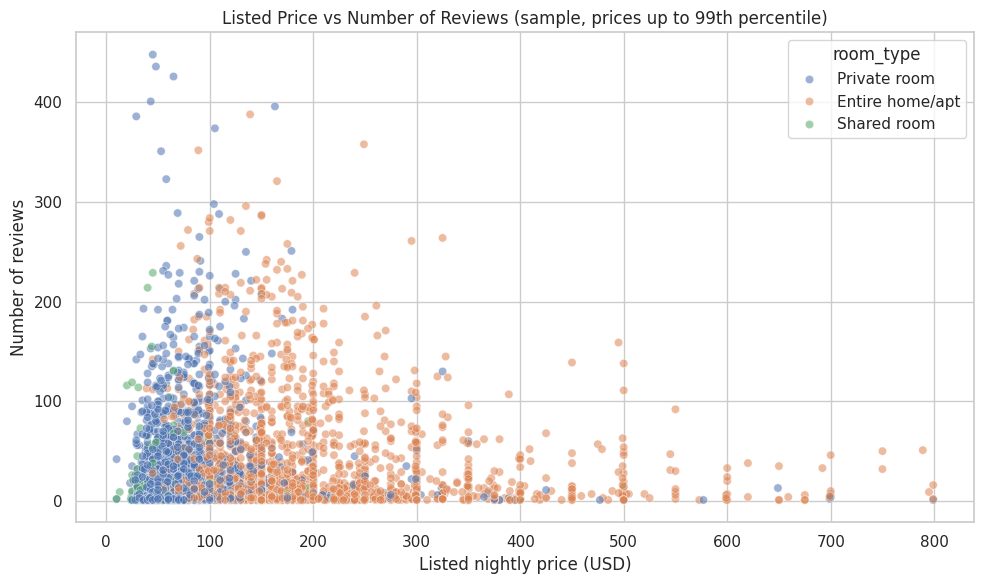

In [16]:
# Sample for readable plotting; all rows remain in the analysis dataset.
scatter_df = df[df["number_of_reviews"] > 0].sample(
    n=min(5000, int((df["number_of_reviews"] > 0).sum())),
    random_state=42
)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=scatter_df[scatter_df["price"] <= price_99],
    x="price", y="number_of_reviews", hue="room_type", alpha=0.55
)
plt.title("Listed Price vs Number of Reviews (sample, prices up to 99th percentile)")
plt.xlabel("Listed nightly price (USD)")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()

### 8.7 Availability by borough

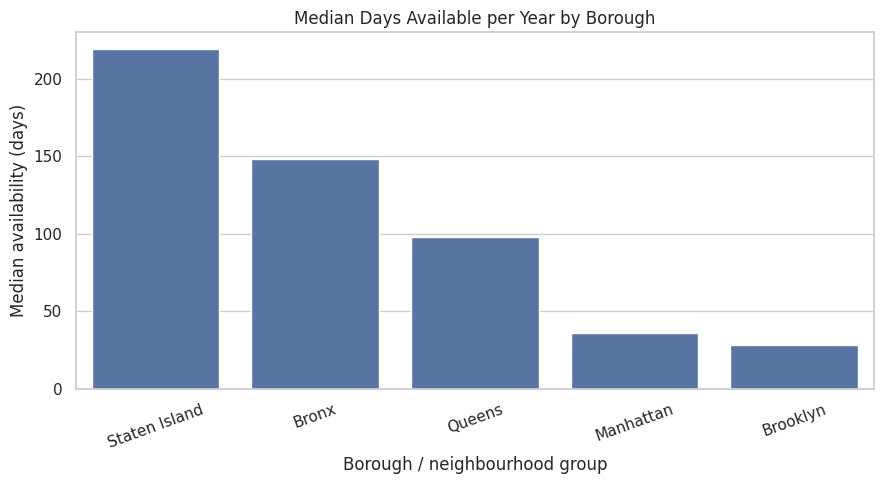

,median_availability_days
neighbourhood_group,
Staten Island,219.00
Bronx,148.00
Queens,98.00
Manhattan,36.00
Brooklyn,28.00


In [17]:
availability_by_borough = (
    df.groupby("neighbourhood_group")["availability_365"]
      .median().sort_values(ascending=False)
)
plt.figure(figsize=(9, 5))
sns.barplot(x=availability_by_borough.index, y=availability_by_borough.values)
plt.title("Median Days Available per Year by Borough")
plt.xlabel("Borough / neighbourhood group")
plt.ylabel("Median availability (days)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
display(availability_by_borough.rename("median_availability_days").to_frame())

### 8.8 Host listing concentration

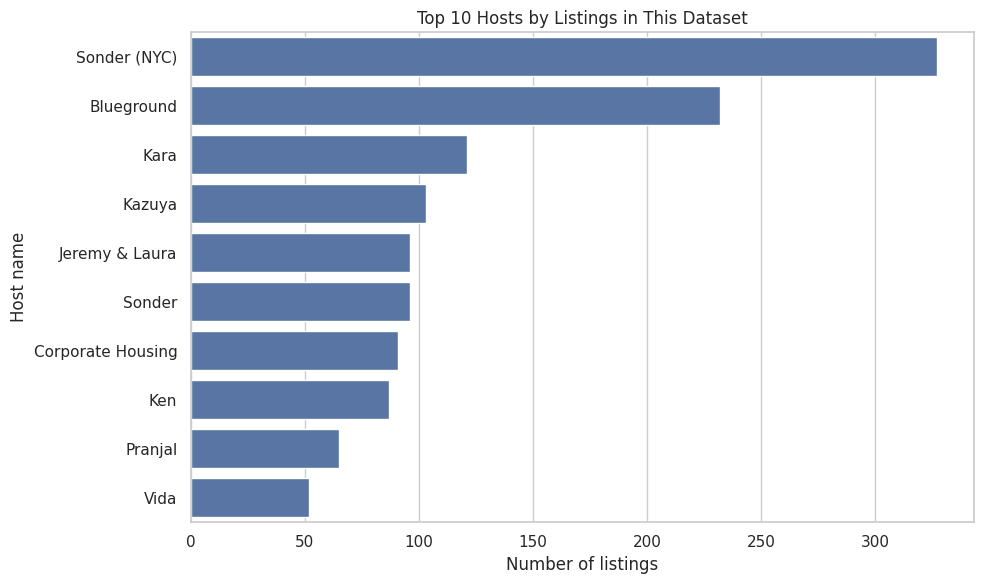

,host_id,host_name,listing_count,median_price
34644,219517861,Sonder (NYC),327,228.00
29405,107434423,Blueground,232,302.50
19572,30283594,Kara,121,239.00
31077,137358866,Kazuya,103,41.00
14434,16098958,Jeremy & Laura,96,180.00
12805,12243051,Sonder,96,209.50
25660,61391963,Corporate Housing,91,142.00
17089,22541573,Ken,87,210.00
33866,200380610,Pranjal,65,250.00
9732,7503643,Vida,52,149.00


In [18]:
top_hosts = (
    df.groupby(["host_id", "host_name"], as_index=False)
      .agg(listing_count=("id", "count"), median_price=("price", "median"))
      .sort_values("listing_count", ascending=False)
      .head(10)
)
plt.figure(figsize=(10, 6))
sns.barplot(data=top_hosts, x="listing_count", y=top_hosts["host_name"].astype(str))
plt.title("Top 10 Hosts by Listings in This Dataset")
plt.xlabel("Number of listings")
plt.ylabel("Host name")
plt.tight_layout()
plt.show()
display(top_hosts)

## 9. SQL analysis with SQLite
The following SQL queries run in Google Colab. We load the cleaned DataFrame into SQLite. SQL results should be interpreted as descriptive listing data, not confirmed bookings or revenue.

In [19]:
# SQLite database lives in memory for this Colab session.
conn = sqlite3.connect(":memory:")
df.to_sql("airbnb", conn, if_exists="replace", index=False)

print(pd.read_sql_query("SELECT COUNT(*) AS total_rows FROM airbnb;", conn))
print(pd.read_sql_query("PRAGMA table_info(airbnb);", conn))

   total_rows
0       48884
    cid                            name       type  notnull dflt_value  pk
0     0                              id    INTEGER        0       None   0
1     1                            name       TEXT        0       None   0
2     2                         host_id    INTEGER        0       None   0
3     3                       host_name       TEXT        0       None   0
4     4             neighbourhood_group       TEXT        0       None   0
5     5                   neighbourhood       TEXT        0       None   0
6     6                        latitude       REAL        0       None   0
7     7                       longitude       REAL        0       None   0
8     8                       room_type       TEXT        0       None   0
9     9                           price    INTEGER        0       None   0
10   10                  minimum_nights    INTEGER        0       None   0
11   11               number_of_reviews    INTEGER        0       None  

### 9.1 Total listings, hosts and neighbourhoods

In [20]:
query = """SELECT
    COUNT(*) AS total_listings,
    COUNT(DISTINCT host_id) AS unique_hosts,
    COUNT(DISTINCT neighbourhood) AS unique_neighbourhoods,
    COUNT(DISTINCT neighbourhood_group) AS boroughs
FROM airbnb;"""
result = pd.read_sql_query(query, conn)
display(result)

,total_listings,unique_hosts,unique_neighbourhoods,boroughs
0,48884,37455,221,5


### 9.2 Listing count and average/median unavailable in basic SQLite by borough

In [21]:
query = """SELECT
    neighbourhood_group,
    COUNT(*) AS total_listings,
    ROUND(AVG(price), 2) AS average_price,
    MIN(price) AS minimum_price,
    MAX(price) AS maximum_price
FROM airbnb
GROUP BY neighbourhood_group
ORDER BY total_listings DESC;"""
result = pd.read_sql_query(query, conn)
display(result)

,neighbourhood_group,total_listings,average_price,minimum_price,maximum_price
0,Manhattan,21660,196.88,10,10000
1,Brooklyn,20095,124.44,10,10000
2,Queens,5666,99.52,10,10000
3,Bronx,1090,87.58,10,2500
4,Staten Island,373,114.81,13,5000


### 9.3 Room-type summary

In [22]:
query = """SELECT
    room_type,
    COUNT(*) AS listings,
    ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM airbnb), 2) AS listing_share_pct,
    ROUND(AVG(price), 2) AS average_price,
    ROUND(AVG(number_of_reviews), 2) AS average_reviews
FROM airbnb
GROUP BY room_type
ORDER BY listings DESC;"""
result = pd.read_sql_query(query, conn)
display(result)

,room_type,listings,listing_share_pct,average_price,average_reviews
0,Entire home/apt,25407,51.97,211.81,22.84
1,Private room,22319,45.66,89.81,24.10
2,Shared room,1158,2.37,70.25,16.62


### 9.4 Neighbourhoods with at least 100 listings

In [23]:
query = """SELECT
    neighbourhood_group,
    neighbourhood,
    COUNT(*) AS listing_count,
    ROUND(AVG(price), 2) AS average_price
FROM airbnb
GROUP BY neighbourhood_group, neighbourhood
HAVING COUNT(*) >= 100
ORDER BY listing_count DESC
LIMIT 20;"""
result = pd.read_sql_query(query, conn)
display(result)

,neighbourhood_group,neighbourhood,listing_count,average_price
0,Brooklyn,Williamsburg,3919,143.84
1,Brooklyn,Bedford-Stuyvesant,3710,107.79
2,Manhattan,Harlem,2658,118.97
3,Brooklyn,Bushwick,2462,84.90
4,Manhattan,Upper West Side,1971,210.92
5,Manhattan,Hell's Kitchen,1958,204.79
6,Manhattan,East Village,1853,186.08
7,Manhattan,Upper East Side,1798,188.95
8,Brooklyn,Crown Heights,1564,112.48
9,Manhattan,Midtown,1545,282.72


### 9.5 Price categories with CASE WHEN

In [24]:
query = """SELECT
    CASE
        WHEN price <= 100 THEN 'Budget (<= $100)'
        WHEN price <= 200 THEN 'Mid-range ($101–200)'
        WHEN price <= 500 THEN 'Premium ($201–500)'
        ELSE 'Luxury (> $500)'
    END AS price_category,
    COUNT(*) AS listings,
    ROUND(AVG(price), 2) AS average_price
FROM airbnb
GROUP BY price_category
ORDER BY MIN(price);"""
result = pd.read_sql_query(query, conn)
display(result)

,price_category,listings,average_price
0,Budget (<= $100),23917,67.89
1,Mid-range ($101–200),16583,150.26
2,Premium ($201–500),7340,296.79
3,Luxury (> $500),1044,"1,123.95"


### 9.6 Hosts with 5 or more listings

In [25]:
query = """SELECT
    host_id,
    host_name,
    COUNT(*) AS listing_count,
    ROUND(AVG(price), 2) AS average_listing_price
FROM airbnb
GROUP BY host_id, host_name
HAVING COUNT(*) >= 5
ORDER BY listing_count DESC, average_listing_price DESC
LIMIT 20;"""
result = pd.read_sql_query(query, conn)
display(result)

,host_id,host_name,listing_count,average_listing_price
0,219517861,Sonder (NYC),327,253.20
1,107434423,Blueground,232,303.15
2,30283594,Kara,121,277.53
3,137358866,Kazuya,103,43.83
4,12243051,Sonder,96,213.03
5,16098958,Jeremy & Laura,96,208.96
6,61391963,Corporate Housing,91,146.24
7,22541573,Ken,87,215.44
8,200380610,Pranjal,65,290.23
9,7503643,Vida,52,149.19


### 9.7 Neighbourhoods with highest median not available in basic SQLite: average price ranking

In [26]:
query = """SELECT
    neighbourhood_group,
    neighbourhood,
    COUNT(*) AS listing_count,
    ROUND(AVG(price), 2) AS average_price
FROM airbnb
GROUP BY neighbourhood_group, neighbourhood
HAVING COUNT(*) >= 30
ORDER BY average_price DESC
LIMIT 15;"""
result = pd.read_sql_query(query, conn)
display(result)

,neighbourhood_group,neighbourhood,listing_count,average_price
0,Manhattan,Tribeca,177,490.64
1,Manhattan,Battery Park City,70,367.56
2,Manhattan,Flatiron District,80,341.93
3,Manhattan,NoHo,78,295.72
4,Manhattan,SoHo,358,287.10
5,Manhattan,Midtown,1545,282.72
6,Manhattan,West Village,768,267.68
7,Manhattan,Greenwich Village,392,263.41
8,Manhattan,Chelsea,1113,249.74
9,Manhattan,Theater District,288,248.01


### 9.8 Listings with high minimum-night requirements

In [27]:
query = """SELECT
    id, name, neighbourhood_group, neighbourhood, room_type,
    price, minimum_nights, availability_365
FROM airbnb
WHERE minimum_nights >= 30
ORDER BY minimum_nights DESC
LIMIT 20;"""
result = pd.read_sql_query(query, conn)
display(result)

,id,name,neighbourhood_group,neighbourhood,room_type,price,minimum_nights,availability_365
0,4204302,Prime W. Village location 1 bdrm,Manhattan,Greenwich Village,Entire home/apt,180,1250,365
1,1615764,Unknown,Manhattan,Battery Park City,Entire home/apt,400,1000,362
2,10053943,Historic Designer 2 Bed. Apartment,Manhattan,Harlem,Entire home/apt,99,999,42
3,20990053,Beautiful place in Brooklyn! #2,Brooklyn,Williamsburg,Private room,79,999,249
4,30378211,Shared Studio (females only),Manhattan,Greenwich Village,Shared room,110,999,365
5,5431845,Beautiful Fully Furnished 1 bed/bth,Queens,Long Island City,Entire home/apt,134,500,90
6,6169897,Wonderful Large 1 bedroom,Manhattan,Harlem,Entire home/apt,75,500,362
7,8668115,Zen Room in Crown Heights Brooklyn,Brooklyn,Crown Heights,Private room,50,500,365
8,11096888,Peaceful apartment close to F/G,Brooklyn,Kensington,Private room,45,500,358
9,35834935,Williamsburg Apartment,Brooklyn,Williamsburg,Entire home/apt,140,500,331


### 9.9 Review activity by room type

In [28]:
query = """SELECT
    room_type,
    COUNT(*) AS listings,
    SUM(number_of_reviews) AS total_reviews,
    ROUND(AVG(number_of_reviews), 2) AS average_reviews_per_listing,
    ROUND(AVG(reviews_per_month), 2) AS average_reviews_per_month
FROM airbnb
GROUP BY room_type
ORDER BY total_reviews DESC;"""
result = pd.read_sql_query(query, conn)
display(result)

,room_type,listings,total_reviews,average_reviews_per_listing,average_reviews_per_month
0,Entire home/apt,25407,580400,22.84,1.05
1,Private room,22319,537979,24.10,1.14
2,Shared room,1158,19249,16.62,1.07


### 9.10 Availability categories

In [29]:
query = """SELECT
    CASE
        WHEN availability_365 <= 30 THEN 'Low (0–30 days)'
        WHEN availability_365 <= 180 THEN 'Medium (31–180 days)'
        ELSE 'High (181–365 days)'
    END AS availability_category,
    COUNT(*) AS listings,
    ROUND(AVG(price), 2) AS average_price
FROM airbnb
GROUP BY availability_category
ORDER BY MIN(availability_365);"""
result = pd.read_sql_query(query, conn)
display(result)

,availability_category,listings,average_price
0,Low (0–30 days),22803,136.67
1,Medium (31–180 days),11720,152.50
2,High (181–365 days),14361,178.51


### 9.11 Window function: rank neighbourhoods by average price

In [30]:
query = """WITH neighbourhood_summary AS (
    SELECT
        neighbourhood_group,
        neighbourhood,
        COUNT(*) AS listing_count,
        AVG(price) AS average_price
    FROM airbnb
    GROUP BY neighbourhood_group, neighbourhood
    HAVING COUNT(*) >= 30
)
SELECT
    neighbourhood_group,
    neighbourhood,
    listing_count,
    ROUND(average_price, 2) AS average_price,
    RANK() OVER (ORDER BY average_price DESC) AS price_rank
FROM neighbourhood_summary
ORDER BY price_rank
LIMIT 20;"""
result = pd.read_sql_query(query, conn)
display(result)

,neighbourhood_group,neighbourhood,listing_count,average_price,price_rank
0,Manhattan,Tribeca,177,490.64,1
1,Manhattan,Battery Park City,70,367.56,2
2,Manhattan,Flatiron District,80,341.93,3
3,Manhattan,NoHo,78,295.72,4
4,Manhattan,SoHo,358,287.10,5
5,Manhattan,Midtown,1545,282.72,6
6,Manhattan,West Village,768,267.68,7
7,Manhattan,Greenwich Village,392,263.41,8
8,Manhattan,Chelsea,1113,249.74,9
9,Manhattan,Theater District,288,248.01,10


### 9.12 Window function: compare each room type to borough average

### 9.13 JOIN: listing count with borough-level summary

In [31]:
query = """
WITH room_summary AS (
    SELECT
        neighbourhood_group,
        room_type,
        COUNT(*) AS listings,
        AVG(price) AS avg_room_price
    FROM airbnb
    GROUP BY neighbourhood_group, room_type
)
SELECT
    neighbourhood_group,
    room_type,
    listings,
    ROUND(avg_room_price, 2) AS avg_room_price,
    ROUND(
        AVG(avg_room_price) OVER (PARTITION BY neighbourhood_group),
        2
    ) AS average_of_room_type_averages_in_borough
FROM room_summary
ORDER BY neighbourhood_group, avg_room_price DESC;
"""
result = pd.read_sql_query(query, conn)
display(result)

,neighbourhood_group,room_type,listings,avg_room_price,average_of_room_type_averages_in_borough
0,Bronx,Entire home/apt,379,127.51,84.73
1,Bronx,Private room,651,66.89,84.73
2,Bronx,Shared room,60,59.80,84.73
3,Brooklyn,Entire home/apt,9558,178.35,101.89
4,Brooklyn,Private room,10126,76.55,101.89
5,Brooklyn,Shared room,411,50.77,101.89
6,Manhattan,Entire home/apt,13198,249.26,151.67
7,Manhattan,Private room,7982,116.78,151.67
8,Manhattan,Shared room,480,88.98,151.67
9,Queens,Entire home/apt,2096,147.05,95.94


### 9.14 Data quality check in SQL

In [32]:
query = """SELECT
    SUM(CASE WHEN price <= 0 THEN 1 ELSE 0 END) AS nonpositive_prices,
    SUM(CASE WHEN minimum_nights <= 0 THEN 1 ELSE 0 END) AS invalid_minimum_nights,
    SUM(CASE WHEN availability_365 < 0 OR availability_365 > 365 THEN 1 ELSE 0 END)
        AS invalid_availability
FROM airbnb;"""
result = pd.read_sql_query(query, conn)
display(result)

,nonpositive_prices,invalid_minimum_nights,invalid_availability
0,0,0,0


## 10. Turn analysis into business insights

## 11. Export files for Power BI and GitHub

In [33]:

import pandas as pd
import os

# 1. Cleaned dataset export
clean_csv = "/content/airbnb_cleaned_for_powerbi.csv"
borough_csv = "/content/airbnb_borough_summary.csv"
room_csv = "/content/airbnb_room_type_summary.csv"
neighbourhood_csv = "/content/airbnb_neighbourhood_summary.csv"

# 2. Borough summary
borough_listing_summary = (
    df.groupby("neighbourhood_group")
      .agg(
          listings=("id", "count"),
          average_price=("price", "mean"),
          median_price=("price", "median")
      )
      .reset_index()
)

# 3. Room type summary
room_summary = (
    df.groupby("room_type")
      .agg(
          listings=("id", "count"),
          average_price=("price", "mean"),
          median_price=("price", "median")
      )
      .reset_index()
)

# 4. Neighbourhood summary
neighbourhood_summary = (
    df.groupby(["neighbourhood_group", "neighbourhood"])
      .agg(
          listings=("id", "count"),
          average_price=("price", "mean"),
          median_price=("price", "median")
      )
      .reset_index()
      .sort_values("listings", ascending=False)
)

# 5. Export all CSV files
df.to_csv(clean_csv, index=False)
borough_listing_summary.to_csv(borough_csv, index=False)
room_summary.to_csv(room_csv, index=False)
neighbourhood_summary.to_csv(neighbourhood_csv, index=False)

# 6. Confirm files were created
print("All files created successfully!")

for p in [clean_csv, borough_csv, room_csv, neighbourhood_csv]:
    print(f"{os.path.basename(p)} — {os.path.getsize(p):,} bytes")


All files created successfully!
airbnb_cleaned_for_powerbi.csv — 8,065,004 bytes
airbnb_borough_summary.csv — 246 bytes
airbnb_room_type_summary.csv — 174 bytes
airbnb_neighbourhood_summary.csv — 9,923 bytes


In [34]:

from google.colab import files

for p in [
    clean_csv,
    borough_csv,
    room_csv,
    neighbourhood_csv
]:
    files.download(p)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Conclusion and Business Recommendations

### Project Conclusion

This project analyzed New York City Airbnb listing data using Python, Pandas, SQL (SQLite), Matplotlib, and Seaborn. The analysis explored listing distribution across neighbourhoods, room-type pricing, review activity, and differences in listing supply.

The results help identify pricing patterns and differences between neighbourhoods and room types. These insights can help Airbnb hosts understand their competitive position and make more informed listing and pricing decisions.

### Business Recommendations

- **Pricing Strategy:** Hosts should compare their listing prices with similar properties in the same neighbourhood before setting nightly rates.
- **Neighbourhood Analysis:** Hosts should consider local listing competition and price differences when choosing where to list a property.
- **Room-Type Selection:** Compare listing counts and average prices across room types before deciding which type to offer.
- **Guest Experience:** Hosts can focus on cleanliness, amenities, accurate descriptions, and guest communication to improve their service.
- **Data-Driven Decisions:** Use summary tables and visualizations to monitor pricing patterns and listing competition.

### Limitations

This dataset contains listing information and review-related metrics. It does not directly establish actual bookings, occupancy rates, or realized revenue. Therefore, the findings describe listing patterns rather than confirmed business earnings.

### Final Outcome

The project demonstrates practical skills in data cleaning, exploratory data analysis, SQL querying, visualization, and translating data into business insights. The exported summary tables can also support further analysis and Power BI dashboard development.

### Before publishing
- Run all cells from top to bottom in a fresh Colab runtime.
- Do not re-upload/re-read the raw CSV after cleaning; this would overwrite the cleaned `df` and SQLite table.
- Keep the original dataset attribution and clearly describe your own work.